# ЛР5. Прогноз оттока клиентов (Telco Customer Churn)

Шаги 1–3: подготовка данных, обучение трёх моделей с 5-fold кросс-валидацией, выбор лучшей и сохранение в `model.pkl`.

Предобработка (заполнение пропусков, one-hot кодирование, масштабирование) входит в `sklearn.Pipeline` (модуль `churn.py`), поэтому сервис получает «сырые» признаки клиента.

In [1]:
import json, platform
from datetime import datetime, timezone
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import pandas as pd
import sklearn
from sklearn.metrics import RocCurveDisplay, accuracy_score, classification_report, f1_score, roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split

from churn import FEATURES, SEED, load_data, make_candidates

print('python', platform.python_version(), '| scikit-learn', sklearn.__version__, '| pandas', pd.__version__)

python 3.12.14 | scikit-learn 1.9.1 | pandas 3.0.6


## Шаг 1. Данные и первичный анализ

In [2]:
raw = pd.read_csv('data/Telco-Customer-Churn.csv')
print(raw.shape)
raw.head(3)

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes


In [3]:
X, y = load_data(Path('data/Telco-Customer-Churn.csv'))
print('Пропуски после приведения типов:', X.isna().sum()[X.isna().sum() > 0].to_dict())
print(f'Доля оттока: {y.mean():.3f} ({y.sum()} из {len(y)})')
X.describe()

Пропуски после приведения типов: {'TotalCharges': 11}
Доля оттока: 0.265 (1869 из 7043)


,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7032.000000
mean,32.371149,64.761692,2283.300441
std,24.559481,30.090047,2266.771362
min,0.000000,18.250000,18.800000
25%,9.000000,35.500000,401.450000
50%,29.000000,70.350000,1397.475000
75%,55.000000,89.850000,3794.737500
max,72.000000,118.750000,8684.800000


Пустые `TotalCharges` (11 клиентов с `tenure = 0`) заполняются медианой внутри пайплайна; категориальные признаки кодируются one-hot, числовые — стандартизируются. Классы несбалансированы (~26,5 % оттока), поэтому используется стратифицированное разбиение.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
print(X_train.shape, X_test.shape)

(5634, 19) (1409, 19)


## Шаг 2. Обучение и выбор модели (5-fold CV)

In [5]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
scoring = {'roc_auc': 'roc_auc', 'f1': 'f1', 'accuracy': 'accuracy'}
rows = []
for name, pipe in make_candidates().items():
    r = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    rows.append({'model': name, **{f'{m}_mean': r[f'test_{m}'].mean() for m in scoring},
                 **{f'{m}_std': r[f'test_{m}'].std() for m in scoring}, 'fit_time_s': r['fit_time'].mean()})
cv_table = pd.DataFrame(rows).set_index('model').sort_values('roc_auc_mean', ascending=False)
cv_table.round(4)

,roc_auc_mean,f1_mean,accuracy_mean,roc_auc_std,f1_std,accuracy_std,fit_time_s
model,,,,,,,
GradientBoosting,0.8486,0.5895,0.8035,0.0118,0.0250,0.0119,1.6285
LogisticRegression,0.8461,0.5930,0.8026,0.0125,0.0298,0.0120,0.1316
RandomForest,0.8449,0.5745,0.8039,0.0099,0.0171,0.0086,1.0644


In [6]:
best_name = cv_table.index[0]
print('Лучшая модель по ROC-AUC на кросс-валидации:', best_name)
best = make_candidates()[best_name].fit(X_train, y_train)
proba = best.predict_proba(X_test)[:, 1]
pred = (proba >= 0.5).astype(int)
test_metrics = {'roc_auc': roc_auc_score(y_test, proba), 'f1': f1_score(y_test, pred), 'accuracy': accuracy_score(y_test, pred)}
print({k: round(v, 4) for k, v in test_metrics.items()})
print(classification_report(y_test, pred, target_names=['остался', 'ушёл']))

Лучшая модель по ROC-AUC на кросс-валидации: GradientBoosting


{'roc_auc': 0.8432, 'f1': 0.5826, 'accuracy': 0.8027}
              precision    recall  f1-score   support

     остался       0.84      0.91      0.87      1035
        ушёл       0.66      0.52      0.58       374

    accuracy                           0.80      1409
   macro avg       0.75      0.71      0.73      1409
weighted avg       0.79      0.80      0.79      1409



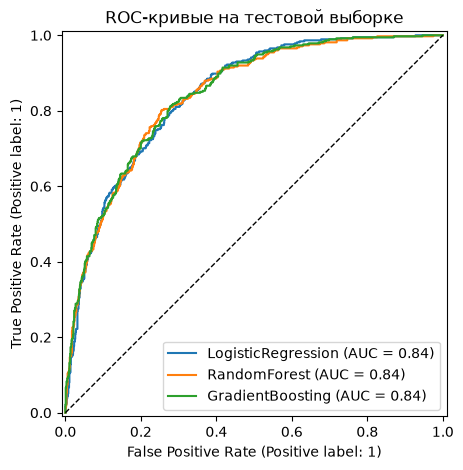

In [7]:
fig, ax = plt.subplots(figsize=(6, 5))
for name, pipe in make_candidates().items():
    RocCurveDisplay.from_estimator(pipe.fit(X_train, y_train), X_test, y_test, name=name, ax=ax)
ax.plot([0, 1], [0, 1], 'k--', lw=1)
ax.set_title('ROC-кривые на тестовой выборке')
fig.savefig('screenshots/roc.png', dpi=130, bbox_inches='tight')

## Шаг 3. Сохранение модели

Сохраняется весь пайплайн (предобработка + модель) и метаданные: версия, метрики, версии библиотек. Версия scikit-learn в Docker-образе должна совпадать с версией при обучении, иначе загрузка pickle не гарантируется.

In [8]:
joblib.dump(best, 'model.pkl')
meta = {
    'model': best_name, 'version': datetime.now(timezone.utc).strftime('%Y%m%d%H%M'),
    'trained_at': datetime.now(timezone.utc).isoformat(timespec='seconds'),
    'sklearn': sklearn.__version__, 'features': FEATURES, 'threshold': 0.5,
    'cv': cv_table.round(4).reset_index().to_dict(orient='records'),
    'test': {k: round(v, 4) for k, v in test_metrics.items()}, 'n_train': len(X_train), 'n_test': len(X_test),
}
Path('model_meta.json').write_text(json.dumps(meta, ensure_ascii=False, indent=1), encoding='utf-8')
print(Path('model.pkl').stat().st_size, 'байт'); meta['model'], meta['test']

276301 байт


('GradientBoosting', {'roc_auc': 0.8432, 'f1': 0.5826, 'accuracy': 0.8027})

In [9]:
# проверка: модель загружается и предсказывает на «сырых» данных
loaded = joblib.load('model.pkl')
sample = X_test.iloc[[0]]
print(sample.to_dict(orient='records')[0])
print('P(отток) =', round(loaded.predict_proba(sample)[0, 1], 4))

{'tenure': 72, 'MonthlyCharges': 114.05, 'TotalCharges': 8468.2, 'gender': 'Male', 'SeniorCitizen': 'No', 'Partner': 'Yes', 'Dependents': 'Yes', 'PhoneService': 'Yes', 'MultipleLines': 'Yes', 'InternetService': 'Fiber optic', 'OnlineSecurity': 'Yes', 'OnlineBackup': 'Yes', 'DeviceProtection': 'Yes', 'TechSupport': 'Yes', 'StreamingTV': 'Yes', 'StreamingMovies': 'Yes', 'Contract': 'Two year', 'PaperlessBilling': 'Yes', 'PaymentMethod': 'Credit card (automatic)'}
P(отток) = 0.0231
